In [1]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from pymongo import MongoClient
import os

# ----------------- CONFIG -----------------
MONGO_URI = "mongodb://localhost:27017/"
DB_NAME = "validation_db"
COLLECTION_NAME = "document_validations"
OUTPUT_DIR = "figures_tables/summary_analysis_output"
os.makedirs(OUTPUT_DIR, exist_ok=True)
# ------------------------------------------

# Define metrics to pull
SUMMARY_KEYS = [
    "ROUGE-1", "ROUGE-2", "ROUGE-L", "ROUGE-Lsum",
    "BERTScore_Precision", "BERTScore_Recall", "BERTScore_F1"
]

# MongoDB projection fields
FIELDS = {f"validation_info.checks.summary_evaluation.{k}": 1 for k in SUMMARY_KEYS}
FIELDS["_id"] = 1
FIELDS["validation_info.checks.text_validation.metrics.abstract_chars"] = 1  # NEW: abstract length

# Connect to MongoDB
client = MongoClient(MONGO_URI)
collection = client[DB_NAME][COLLECTION_NAME]

# Filter: skip documents where all values are exactly 0.0
non_zero_filter = {
    "$and": [
        {
            "$or": [
                {f"validation_info.checks.summary_evaluation.{k}": {"$ne": 0.0}}
                for k in SUMMARY_KEYS
            ]
        },
        {"validation_info.checks.text_validation.flags.language_mismatch_or_low_confidence": False},
        # {"validation_info.checks.text_validation.flags.abstract_too_short": False},
        # {"validation_info.checks.text_validation.flags.abstract_low_ascii_ratio": False},
        # {"validation_info.checks.text_validation.metrics.abstract_sentence_count": {"$gte": 2}},
        # {"validation_info.checks.text_validation.metrics.rouge1_recall": {"$gte": 0.3}}
    ]
}

# Query and load
cursor = collection.find(non_zero_filter, FIELDS)
docs = list(cursor)
client.close()

# Flatten nested fields
df = pd.json_normalize(docs)

# Rename metric columns
df.rename(columns={f"validation_info.checks.summary_evaluation.{k}": k for k in SUMMARY_KEYS}, inplace=True)
df.rename(columns={"validation_info.checks.text_validation.metrics.abstract_chars": "Abstract_Chars"}, inplace=True)

# Drop rows with missing values in the main metrics
df.dropna(subset=SUMMARY_KEYS, inplace=True)

# ----------------- STATISTICS TABLE -----------------
print("\n📊 Descriptive Statistics (non-zero only):")
print(df[SUMMARY_KEYS + ["Abstract_Chars"]].describe().round(2))

# ----------------- CORRELATION HEATMAP -----------------




📊 Descriptive Statistics (non-zero only):
         ROUGE-1    ROUGE-2    ROUGE-L  ROUGE-Lsum  BERTScore_Precision  \
count  495119.00  495119.00  495119.00   495119.00            495119.00   
mean       34.30      20.16      26.40       30.28                38.02   
std        11.41       9.25      10.60       10.37                10.70   
min         0.00       0.00       0.00        0.00               -29.71   
25%        26.77      14.29      19.44       23.43                31.76   
50%        31.97      18.12      24.05       28.21                36.30   
75%        39.07      23.39      30.43       34.59                41.71   
max       100.00     100.00     100.00      100.00               100.00   

       BERTScore_Recall  BERTScore_F1  Abstract_Chars  
count         495119.00     495119.00       495119.00  
mean              67.85         50.74         1299.15  
std                6.73          8.17          542.96  
min              -24.20        -22.75            1.00  
2

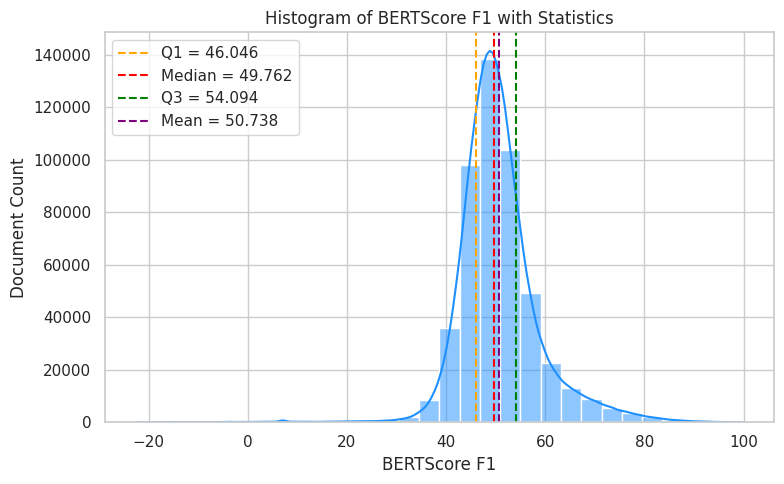

In [2]:
import numpy as np

sns.set(style="whitegrid")

# 1. Histogram of BERTScore F1
plt.figure(figsize=(8, 5))
sns.histplot(df["BERTScore_F1"], bins=30, kde=True, color="dodgerblue")

# Calculate quartiles and statistics
q1 = df["BERTScore_F1"].quantile(0.25)
q2 = df["BERTScore_F1"].quantile(0.50)  # median
q3 = df["BERTScore_F1"].quantile(0.75)
mean_val = df["BERTScore_F1"].mean()

# Add vertical lines
lines = []
labels = []

for val, label, color in [
    (q1, "Q1", "orange"),
    (q2, "Median", "red"),
    (q3, "Q3", "green"),
    (mean_val, "Mean", "purple")
]:
    line = plt.axvline(val, color=color, linestyle="--", linewidth=1.5)
    lines.append(line)
    labels.append(f"{label} = {val:.3f}")

# Add legend
plt.legend(lines, labels, loc="upper left", frameon=True)

plt.title("Histogram of BERTScore F1 with Statistics")
plt.xlabel("BERTScore F1")
plt.ylabel("Document Count")
plt.tight_layout()
plt.savefig(os.path.join(OUTPUT_DIR, "Histogram_BERTScore_F1.png"), bbox_inches="tight")
plt.show()


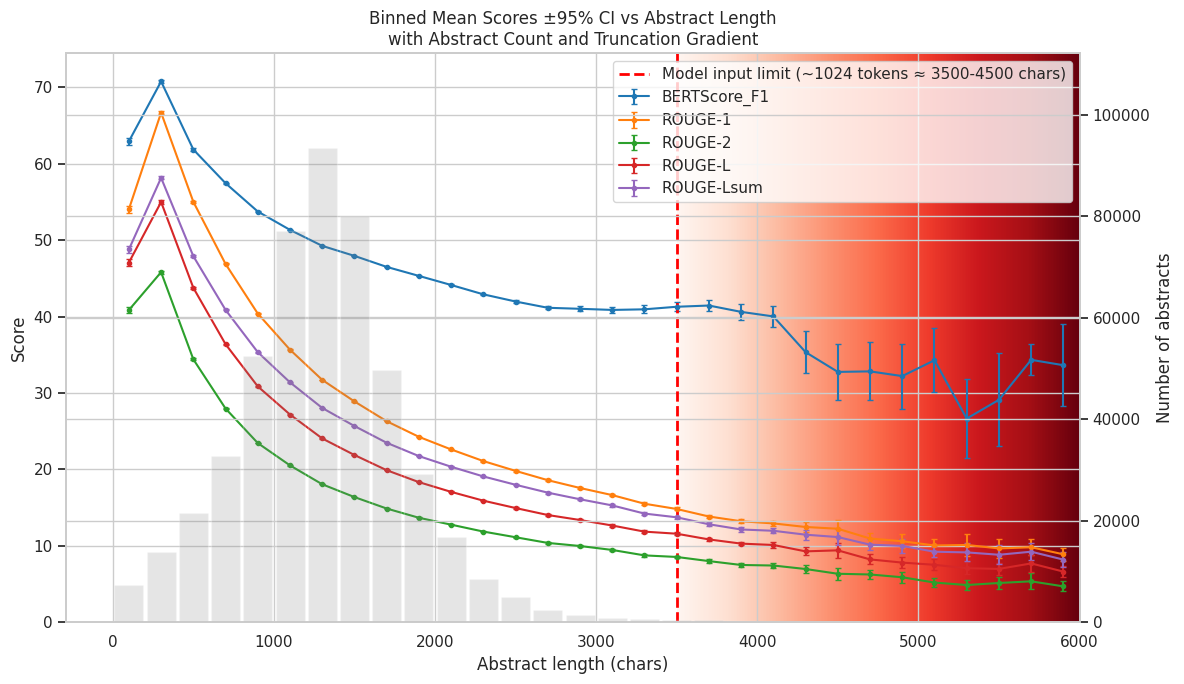

In [3]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import os

# Output directory
OUTPUT_DIR = "figures_tables/summary_analysis_output"
os.makedirs(OUTPUT_DIR, exist_ok=True)

# Metrics to plot
metrics_to_plot = ["BERTScore_F1", "ROUGE-1", "ROUGE-2", "ROUGE-L", "ROUGE-Lsum"]

# Create bins for abstract length
bins = np.arange(0, df["Abstract_Chars"].clip(upper=6000).max() + 1, 200)
df["bin"] = pd.cut(df["Abstract_Chars"], bins, right=False)

# Compute stats
stats = {}
for metric in metrics_to_plot:
    tmp = (
        df.groupby("bin")[metric]
          .agg(mean="mean", n="size", std="std")
          .reset_index()
    )
    tmp["ci"] = 1.96 * tmp["std"] / np.sqrt(tmp["n"])
    tmp["center"] = [b.left + (b.right - b.left) / 2 for b in tmp["bin"]]
    stats[metric] = tmp

# Counts for bar plot
bin_counts = df.groupby("bin").size().reset_index(name="count")
bin_centers = [b.left + (b.right - b.left) / 2 for b in bin_counts["bin"]]

# Input limit (chars)
approx_char_limit = 3500
max_char_len = 6000 #df["Abstract_Chars"].max()

# --- Plot ---
fig, ax1 = plt.subplots(figsize=(12, 7))

# Background bar plot (abstract counts)
ax2 = ax1.twinx()
ax2.bar(bin_centers, bin_counts["count"], width=180, alpha=0.2, color="gray", label="Abstract count")
ax2.set_ylabel("Number of abstracts")
ax2.set_ylim(0, bin_counts["count"].max() * 1.2)

# Create gradient shadow from approx_char_limit to max_char_len
n_steps = 300  # smoothness of gradient
gradient = np.linspace(0.05, 0.25, n_steps).reshape(1, -1)  # alpha from light to darker
extent = [approx_char_limit, max_char_len, 0, 1]  # x_min, x_max, y_min, y_max (normalized y)
ax1.imshow(
    gradient,
    aspect="auto",
    cmap="Reds",
    extent=extent,
    alpha=1.0,
    transform=ax1.get_xaxis_transform()
)

# Main line plots
colors = sns.color_palette("tab10", len(metrics_to_plot))
for metric, color in zip(metrics_to_plot, colors):
    tmp = stats[metric]
    ax1.errorbar(
        tmp["center"], tmp["mean"], yerr=tmp["ci"],
        fmt="-o", ms=3, capsize=2, label=metric, color=color
    )

# Vertical dashed line at truncation start
ax1.axvline(
    x=approx_char_limit,
    color="red",
    linestyle="--",
    linewidth=2,
    label="Model input limit (~1024 tokens ≈ 3500-4500 chars)"
)

# Labels, title, legend
ax1.set_xlabel("Abstract length (chars)")
ax1.set_ylabel("Score")
ax1.set_title("Binned Mean Scores ±95% CI vs Abstract Length\nwith Abstract Count and Truncation Gradient")
ax1.legend(loc="upper right")
plt.tight_layout()

# Save & show
plt.savefig(os.path.join(OUTPUT_DIR, "AllScores_vs_Length_binned_with_counts_and_gradient.png"), bbox_inches="tight")
plt.show()


/tmp/ipykernel_1697597/1077111342.py:38: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(


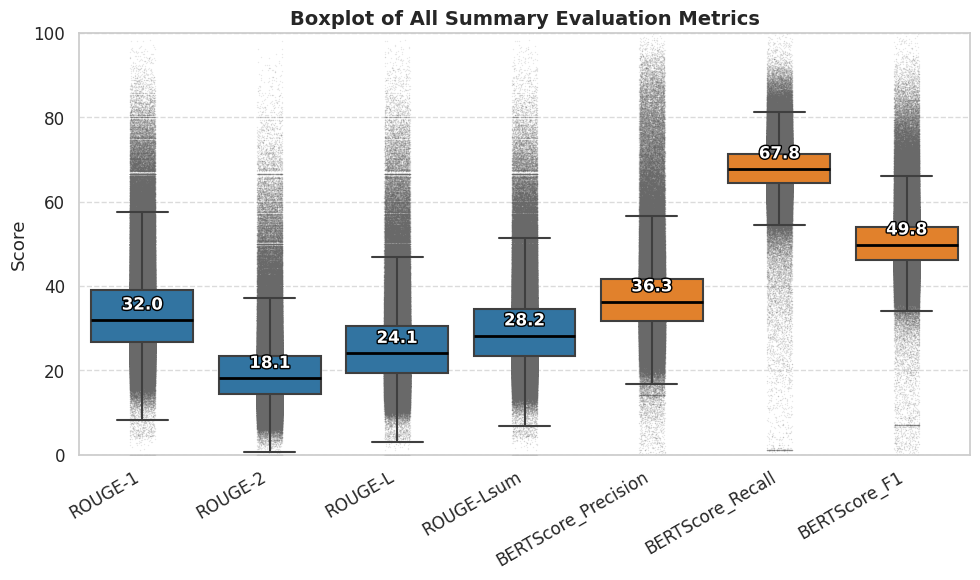

In [4]:
import seaborn as sns
import matplotlib.pyplot as plt
import os
import matplotlib.patheffects as path_effects
import pandas as pd

# Ensure metrics are in logical order
metrics_order = [
    "ROUGE-1", "ROUGE-2", "ROUGE-L", "ROUGE-Lsum",
    "BERTScore_Precision", "BERTScore_Recall", "BERTScore_F1"
]

# Melt DataFrame & preserve order
df_melt = df[metrics_order].melt(var_name="Metric", value_name="Score")
df_melt["Metric"] = pd.Categorical(df_melt["Metric"], categories=metrics_order, ordered=True)

# Color palette: ROUGE = blue, BERTScore = orange
palette = {
    "ROUGE-1": "#1f77b4",
    "ROUGE-2": "#1f77b4",
    "ROUGE-L": "#1f77b4",
    "ROUGE-Lsum": "#1f77b4",
    "BERTScore_Precision": "#ff7f0e",
    "BERTScore_Recall": "#ff7f0e",
    "BERTScore_F1": "#ff7f0e"
}

sns.set_theme(style="whitegrid", font_scale=1.1)
plt.figure(figsize=(10, 6))

# Scatter points first (so they go behind boxplot)
sns.stripplot(
    x="Metric", y="Score", data=df_melt,
    color="dimgray", size=1, jitter=True, alpha=0.15, zorder=1
)

# Boxplot on top
sns.boxplot(
    x="Metric", y="Score", data=df_melt,
    palette=palette, showfliers=False,
    linewidth=1.5,
    medianprops=dict(color="black", linewidth=2),
    zorder=2
)

# Add median labels above each box
medians = df_melt.groupby("Metric")["Score"].median()
for i, median in enumerate(medians):
    plt.text(
        i, median + 1.5, f"{median:.1f}",
        ha="center", va="bottom",
        fontsize=12, fontweight="bold", color="white",
        path_effects=[path_effects.withStroke(linewidth=2, foreground="black")]
    )

# Titles & labels
plt.title("Boxplot of All Summary Evaluation Metrics", fontsize=14, fontweight="bold")
plt.ylabel("Score")
plt.xlabel("")
plt.xticks(rotation=30, ha="right")
plt.ylim(0, 100)
plt.grid(axis="y", linestyle="--", alpha=0.7)

plt.tight_layout()
plt.savefig(os.path.join(OUTPUT_DIR, "Boxplot_for_all_metrics_polished.png"), bbox_inches="tight")
plt.show()


In [5]:
# 5. Top 10 summaries by BERTScore F1
print("\n🏆 Top 10 documents by BERTScore F1:")
top10 = df.sort_values("BERTScore_F1", ascending=False).head(10)
print(top10[["_id", "BERTScore_F1", "ROUGE-L", "ROUGE-2"]])


🏆 Top 10 documents by BERTScore F1:
              _id  BERTScore_F1     ROUGE-L     ROUGE-2
27296    12365435    100.000024  100.000000  100.000000
109314   20943318     99.741232   96.666667   93.103448
26039    12082071     99.209911   93.103448   85.714286
284502  251878810     99.168199   98.412698   95.081967
262881  246775104     99.082994  100.000000  100.000000
107934   20912829     98.889720   95.238095   88.524590
334297  264363428     98.724174   93.877551   89.361702
418205   53437979     98.653865   89.655172   82.142857
207112  233470242     98.493969  100.000000  100.000000
177040  225492135     98.492700   94.915254   91.228070


In [6]:
# 6. Bottom 10 summaries by BERTScore F1
print("\n⚠️ Bottom 10 documents by BERTScore F1:")
bottom10 = df.sort_values("BERTScore_F1", ascending=True).head(10)
print(bottom10[["_id", "BERTScore_F1", "ROUGE-L", "ROUGE-2"]])



⚠️ Bottom 10 documents by BERTScore F1:
              _id  BERTScore_F1    ROUGE-L   ROUGE-2
29540    12815712    -22.747943   0.000000  0.000000
15142   105107368    -21.089645   2.298851  0.000000
478813   91198681    -21.087441   7.407407  3.846154
247311  239521700    -21.062465   0.000000  0.000000
468778   83875702    -20.426530   0.000000  0.000000
465500   78773336    -20.073166  12.244898  4.255319
201993  232216892    -19.284578   0.000000  0.000000
494467   99695702    -19.094117  26.229508  3.389831
46174   148898811    -18.942939   2.941176  0.000000
137487  216336456    -18.715337   3.703704  0.000000
